# Azure Pod Trace 2026

This notebook analyzes the Azure Kubernetes Service (AKS) pod traces released with
[Unipool](https://doi.org/10.1145/3828523.3857110) (SIGOPS ATC 2026).
See the [dataset description](../../AzurePodDataset2026.md).

We use pods with recorded creation and deletion times and lifetimes from 2 seconds to one week.

## Setup

Import packages and set the plot style.

In [1]:
import hashlib
import io
import json
import tarfile
import time
import urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

ARCHIVE_PATH = Path("downloaded_data") / "AzurePodDataset2026.tar.gz"
plt.rcParams.update({
    "figure.dpi": 150, "figure.constrained_layout.use": True,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 16, "axes.titlesize": 16, "axes.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=["#4492c5", "#5bb95c", "#ec3424"]),
    "axes.grid": True, "grid.color": "black", "grid.alpha": 0.6,
    "grid.linewidth": 0.4, "grid.linestyle": (0, (1, 4)),
    "lines.linewidth": 2, "lines.dash_capstyle": "round",
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 8, "ytick.major.size": 8,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "legend.frameon": False, "legend.handlelength": 1,
    "legend.handletextpad": 0.3, "legend.borderpad": 0, "legend.labelspacing": 0,
})

## Load the trace

The first run downloads and verifies the 1.64 GiB trace in `downloaded_data/`.
Reading the trace takes several minutes.

### Download and verification

Download the archive and check its size and SHA-256 checksum.

In [2]:
# Release archive, CSV schema, and verified download
ARCHIVE_URL = ("https://github.com/Azure/AzurePublicDataset/releases/download/"
               "dataset-pods-2026/AzurePodDataset2026.tar.gz")
ARCHIVE_SHA256 = "950386a6017c8ae855fa6010e13d6fc7e5edf2fde9555e1724f7aeddb4acfe8d"
ARCHIVE_BYTES = 1_756_175_802
SHARDS = 672                      # 15-minute creation windows over 7 days
SHARD_MS = 15 * 60 * 1000
DAY_MS = 24 * 60 * 60 * 1000
SHARDS_PER_DAY = DAY_MS // SHARD_MS
MINUTE_MS, TEN_MINUTES_MS, HOUR_MS = 60_000, 600_000, 3_600_000
MIN_LIFETIME_MS, MAX_LIFETIME_MS = 2_000, 7 * DAY_MS   # analysis cohort, both bounds inclusive
COHORT_RULE = "known deleted_time and 2000 <= deleted_time - created_time <= 604800000 ms"
MAX_METADATA_BYTES = 16 * 1024 * 1024
COLUMNS = ["invocation_id", "customer_id", "container_group_id", "created_time",
           "deleted_time", "requested_cpu", "requested_memory_mib", "limit_cpu",
           "limit_memory_mib", "num_containers", "has_all_cpu_limits", "has_all_mem_limits"]
# CSV units per core (CPU, millicores) and per GiB (memory, MiB).
RESOURCES = {"requested_cpu": ("cpu_request", 1000), "limit_cpu": ("cpu_limit", 1000),
             "requested_memory_mib": ("memory_request", 1024),
             "limit_memory_mib": ("memory_limit", 1024)}
LIMITS = [("limit_cpu", "requested_cpu", "has_all_cpu_limits"),
          ("limit_memory_mib", "requested_memory_mib", "has_all_mem_limits")]


def require(condition, message):
    if not condition:
        raise ValueError(message)


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 23), b""):
            digest.update(block)
    return digest.hexdigest()


def verify_archive(path, sha256=None, size=None):
    """Check the archive size and SHA-256 against the pinned release."""
    sha256 = ARCHIVE_SHA256 if sha256 is None else sha256
    size = ARCHIVE_BYTES if size is None else size
    path = Path(path)
    found_size, found_sha256 = path.stat().st_size, file_sha256(path)
    if (found_size, found_sha256) != (size, sha256):
        raise ValueError(
            f"{path.name} is {found_size:,} bytes with SHA-256 {found_sha256}, but this notebook "
            f"expects {size:,} bytes with SHA-256 {sha256} (release dataset-pods-2026). The file "
            "was left unchanged. Check that it is a complete download of that release, or use "
            "the notebook version that matches your release.")
    return {"bytes": found_size, "sha256": found_sha256}


def download_archive(path, url=None, sha256=None, size=None):
    """Download to a .part file and rename it only after the checksum matches.

    An existing file is verified and never replaced.
    """
    url = ARCHIVE_URL if url is None else url
    sha256 = ARCHIVE_SHA256 if sha256 is None else sha256
    size = ARCHIVE_BYTES if size is None else size
    path = Path(path)
    if path.exists():
        return verify_archive(path, sha256, size)
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_name(path.name + ".part")
    digest, received, reported = hashlib.sha256(), 0, 0
    with urllib.request.urlopen(url, timeout=60) as response, open(partial, "wb") as output:
        for block in iter(lambda: response.read(1 << 23), b""):
            output.write(block)
            digest.update(block)
            received += len(block)
            if received - reported >= 256 * 2**20:
                reported = received
                print(f"Downloaded {received / 2**30:.2f} of {size / 2**30:.2f} GiB", flush=True)
    if (received, digest.hexdigest()) != (size, sha256):
        raise ValueError(
            f"Download returned {received:,} bytes with SHA-256 {digest.hexdigest()}; expected "
            f"{size:,} bytes with SHA-256 {sha256} (release dataset-pods-2026). {path.name} was "
            f"not created and {partial.name} was kept for inspection. Verify the release version "
            "before retrying.")
    partial.replace(path)
    return {"bytes": received, "sha256": sha256}

### Field parsing

Parse timestamps and resource values, and track arrivals for each pool.

In [3]:
# Field parsing and pool inter-arrival updates
def parse_integers(text, name):
    """Exact int64 values from CSV text; any non-integer literal is an error."""
    if len(text) == 0:
        return np.empty(0, dtype=np.int64)
    values = pd.to_numeric(text, errors="coerce")
    require(values.dtype == np.int64, f"{name}: expected integer values")
    return values.to_numpy()


def parse_amounts(text, name):
    """Resource values as floats; NaN marks an empty (missing) field."""
    raw = text.to_numpy()
    present = raw != ""
    amounts = np.full(len(raw), np.nan)
    amounts[present] = raw[present].astype(float)
    require(np.isfinite(amounts[present]).all() and (amounts[present] >= 0).all(),
            f"{name}: values must be finite and nonnegative")
    return amounts, present


def require_power_of_two(amounts, units, name):
    """Positive amounts must be exact powers of two in cores or GiB."""
    mantissa, _ = np.frexp(amounts[amounts > 0] / units)
    require((mantissa == 0.5).all(), f"{name}: expected powers of two in cores/GiB")


def update_pools(pools, bundles, created):
    """Add one shard to per-bundle [arrivals, first, last, min gap, max gap] (ms).

    Rows are in creation order. The gap from a bundle's last arrival in earlier
    shards to its first arrival in this shard is included, and so are zero gaps
    between simultaneous arrivals.
    """
    if len(bundles) == 0:
        return
    frame = pd.DataFrame({"bundle": bundles, "created": created})
    times = frame.groupby("bundle", sort=False)["created"]
    summary = times.agg(["count", "min", "max"])
    gaps = times.diff().groupby(frame["bundle"], sort=False).agg(["min", "max"])
    summary = summary.join(gaps.set_axis(["min_gap", "max_gap"], axis=1))
    for bundle, count, first, last, low, high in summary.itertuples(name=None):
        low = None if pd.isna(low) else int(low)
        high = None if pd.isna(high) else int(high)
        old = pools.get(bundle)
        if old is None:
            pools[bundle] = [int(count), int(first), int(last), low, high]
            continue
        bridge = int(first) - old[2]
        require(bridge >= 0, "pool arrivals moved backwards in time")
        lows = [g for g in (old[3], low, bridge) if g is not None]
        highs = [g for g in (old[4], high, bridge) if g is not None]
        pools[bundle] = [old[0] + int(count), old[1], int(last), min(lows), max(highs)]

### Trace aggregation

Apply the lifetime filter and collect lifetime, arrival, and resource statistics.

In [4]:
# Per-shard validation and aggregation
class PodTraceScan:
    """Shard-by-shard state: integrity counters over all rows, plus exact
    lifetime, pool arrival, per-shard and resource counts for the analysis cohort only."""

    def __init__(self):
        self.next_invocation_id = 1
        self.last_created = None
        self.raw = Counter()                # all rows; compared with the manifest
        self.excluded = Counter()           # pods outside the cohort, by reason
        self.namespaces = set()
        self.bundle_containers = {}         # every bundle -> num_containers
        self.lifetimes = Counter()          # cohort lifetime (ms) -> pods
        self.pools = {}                     # cohort bundle -> [arrivals, first, last, min gap, max gap]
        self.windows = []                   # (shard index, cohort pods created in it), every shard
        self.resources = {column: Counter() for column in RESOURCES}  # cohort amount (cores/GiB) -> pods

    def add_shard(self, frame, index, entry):
        name = entry["name"]
        require(frame.columns.tolist() == COLUMNS, f"{name}: unexpected CSV header")
        require(len(frame) == entry["rows"] and len(frame) > 0, f"{name}: row count differs from manifest")
        require(not frame.isna().any().any(), f"{name}: rows with too few fields")
        ids = parse_integers(frame["invocation_id"], f"{name}: invocation_id")
        require(ids[0] == self.next_invocation_id == entry["first_invocation_id"]
                and ids[-1] == entry["last_invocation_id"] and (np.diff(ids) == 1).all(),
                f"{name}: invocation IDs are not consecutive across shards")
        created = parse_integers(frame["created_time"], f"{name}: created_time")
        require((np.diff(created) >= 0).all() and created[0] >= (self.last_created or 0),
                f"{name}: creation times decrease")
        start = index * SHARD_MS
        require(((created >= start) & (created < start + SHARD_MS)).all(),
                f"{name}: creation time outside its 15-minute window")
        for column in ("customer_id", "container_group_id"):
            require(frame[column].ne("").all(), f"{name}: empty {column}")
        bundles = frame["container_group_id"].to_numpy()
        containers = parse_integers(frame["num_containers"], f"{name}: num_containers")
        require((containers > 0).all(), f"{name}: num_containers must be positive")
        self._check_bundle_containers(bundles, containers, name)

        amounts = {}
        for column, (label, units) in RESOURCES.items():
            values, present = parse_amounts(frame[column], f"{name}: {column}")
            require_power_of_two(values, units, f"{name}: {column}")
            self.raw[label + "_missing"] += int((~present).sum())
            self.raw[label + "_zero"] += int((values == 0).sum())
            amounts[column] = values
        require((amounts["requested_cpu"] > 0).all(), f"{name}: CPU requests must be present and positive")
        require(np.isfinite(amounts["requested_memory_mib"]).all(), f"{name}: missing memory request")
        for limit, request, flag in LIMITS:
            require(frame[flag].isin(["true", "false"]).all(), f"{name}: {flag} must be true/false")
            present = np.isfinite(amounts[limit])
            require(np.array_equal(present, frame[flag].eq("true").to_numpy()),
                    f"{name}: {flag} disagrees with blank/present {limit}")
            require((amounts[limit][present] >= amounts[request][present]).all(),
                    f"{name}: {limit} below {request}")

        known = frame["deleted_time"].ne("").to_numpy()
        lifetime = parse_integers(frame.loc[known, "deleted_time"], f"{name}: deleted_time") - created[known]
        require((lifetime >= 0).all(), f"{name}: deletion before creation")
        self.raw["rows"] += len(frame)
        self.raw["known_deletions"] += int(known.sum())
        self.raw["missing_deletions"] += int((~known).sum())
        self.namespaces.update(frame["customer_id"].unique().tolist())

        # Analysis cohort, applied before any lifetime or pool update: a row outside
        # it neither creates a pool nor splits the interval between cohort arrivals.
        in_range = (lifetime >= MIN_LIFETIME_MS) & (lifetime <= MAX_LIFETIME_MS)
        selected = np.zeros(len(frame), dtype=bool)
        selected[known] = in_range
        self.excluded["missing_deletion"] += int((~known).sum())
        self.excluded["below_2s"] += int((lifetime < MIN_LIFETIME_MS).sum())
        self.excluded["above_1week"] += int((lifetime > MAX_LIFETIME_MS).sum())
        values, counts = np.unique(lifetime[in_range], return_counts=True)
        self.lifetimes.update(dict(zip(values.tolist(), counts.tolist())))
        update_pools(self.pools, bundles[selected], created[selected])
        self.windows.append((index, int(selected.sum())))
        for column, (_, units) in RESOURCES.items():
            chosen = amounts[column][selected]          # missing limits (NaN) are not counted; zeros are
            values, counts = np.unique(chosen[np.isfinite(chosen)] / units, return_counts=True)
            self.resources[column].update(dict(zip(values.tolist(), counts.tolist())))
        self.next_invocation_id = int(ids[-1]) + 1
        self.last_created = int(created[-1])

    def _check_bundle_containers(self, bundles, containers, name):
        sizes = pd.Series(containers).groupby(bundles, sort=False).agg(["min", "max"])
        require((sizes["min"] == sizes["max"]).all(), f"{name}: num_containers changes within an image bundle")
        for bundle, count in sizes["min"].items():
            require(self.bundle_containers.setdefault(bundle, int(count)) == int(count),
                    f"{name}: num_containers changes for an image bundle across shards")

    def summarize(self):
        """Return (raw, selected, aggregates). Counts only, so an empty cohort is safe.

        aggregates (cohort pods only, no identifiers):
          lifetimes: lifetime_ms, pods
          pools: arrivals, mean_iat_s, min_iat_s, max_iat_s (pools with >= 2 pods)
          windows: window (shard index), pods (created in that 15-minute shard)
          resources[CSV column]: amount (cores for CPU, GiB for memory), pods;
            zero amounts are kept and missing limits are omitted
        """
        raw = {key: int(self.raw[key]) for key in ("rows", "known_deletions", "missing_deletions")}
        raw.update(namespaces=len(self.namespaces), bundles=len(self.bundle_containers))
        raw.update({key: int(self.raw[key]) for label, _ in RESOURCES.values()
                    for key in (label + "_missing", label + "_zero")})

        lifetimes = pd.DataFrame(sorted(self.lifetimes.items()), columns=["lifetime_ms", "pods"], dtype="int64")
        life_ms, life_n = lifetimes["lifetime_ms"].to_numpy(), lifetimes["pods"].to_numpy()
        table = pd.DataFrame(list(self.pools.values()),
                             columns=["arrivals", "first_ms", "last_ms", "min_gap_ms", "max_gap_ms"])
        valid = table[table["arrivals"] >= 2]
        intervals = valid["arrivals"].to_numpy(np.int64) - 1
        span = valid["last_ms"].to_numpy(np.int64) - valid["first_ms"].to_numpy(np.int64)
        min_gap = valid["min_gap_ms"].astype(float).to_numpy(np.int64)
        max_gap = valid["max_gap_ms"].astype(float).to_numpy(np.int64)
        pools = pd.DataFrame({"arrivals": intervals + 1, "mean_iat_s": span / intervals / 1000,
                              "min_iat_s": min_gap / 1000, "max_iat_s": max_gap / 1000})

        selected = {
            "rule": COHORT_RULE,
            "pods": int(life_n.sum()),
            "excluded_pods": raw["rows"] - int(life_n.sum()),
            **{"excluded_" + k: int(self.excluded[k]) for k in ("missing_deletion", "below_2s", "above_1week")},
            "lifetime_below_10min": int(life_n[life_ms < TEN_MINUTES_MS].sum()),
            "lifetime_below_1hour": int(life_n[life_ms < HOUR_MS].sum()),
            "bundles": len(table),
            "singleton_bundles": int((table["arrivals"] == 1).sum()),
            "valid_bundles": len(valid),
            "zero_mean_bundles": int((span == 0).sum()),
            "mean_iat_above_1min": int((span > MINUTE_MS * intervals).sum()),
            "mean_iat_above_1hour": int((span > HOUR_MS * intervals).sum()),
            "min_iat_above_1min": int((min_gap > MINUTE_MS).sum()),
            "min_iat_above_1hour": int((min_gap > HOUR_MS).sum()),
            "max_iat_above_1min": int((max_gap > MINUTE_MS).sum()),
            "max_iat_above_1hour": int((max_gap > HOUR_MS).sum()),
            "zero_min_iat_bundles": int((min_gap == 0).sum()),
        }
        windows = pd.DataFrame(self.windows, columns=["window", "pods"], dtype="int64")
        resources = {column: pd.DataFrame(sorted(counter.items()), columns=["amount", "pods"])
                     .astype({"amount": float, "pods": "int64"}) for column, counter in self.resources.items()}
        return raw, selected, {"lifetimes": lifetimes, "pools": pools, "windows": windows, "resources": resources}

### Archive scanning

Check the manifest and trace files, then scan the complete archive.

In [5]:
# Manifest checks and the full archive scan
def check_manifest(manifest, readme_sha256, shards):
    require(isinstance(manifest, dict), "manifest.json is not a JSON object")
    files = manifest.get("files")
    require(manifest.get("description_sha256") == readme_sha256, "manifest does not match the archive README.md")
    require(manifest.get("columns") == COLUMNS, "manifest columns differ from the documented schema")
    require(manifest.get("window_count") == shards and manifest.get("trace_window_ms") == shards * SHARD_MS
            and isinstance(files, list) and len(files) == shards,
            f"manifest does not describe {shards} 15-minute windows")
    require([f.get("name") for f in files] == [f"part_{i:04d}.csv" for i in range(shards)],
            "manifest shard names are not part_0000.csv, part_0001.csv, ... in order")


def check_totals(manifest, raw):
    """Compare all-row counts (not the analysis cohort) with the manifest."""
    expected = manifest["row_statistics"]
    pairs = {"rows": "rows", "missing_deletion": "missing_deletions",
             "missing_cpu_limits": "cpu_limit_missing", "missing_memory_limits": "memory_limit_missing",
             "zero_requested_memory": "memory_request_zero", "zero_memory_limits": "memory_limit_zero"}
    for key, ours in pairs.items():
        require(expected[key] == raw[ours], f"manifest {key} is {expected[key]:,}; the scan found {raw[ours]:,}")
    require(manifest["customer_groups"] == raw["namespaces"], "namespace count differs from manifest")
    require(manifest["container_groups"] == raw["bundles"], "image-bundle count differs from manifest")


def scan_archive(path, verbose=True):
    """Verify and scan the complete release. Returns (analysis_result, aggregates).

    Members must be exactly README.md, manifest.json and the manifest's CSV
    shards in order; each shard is read into memory, checked against its
    manifest SHA-256, byte count and row count, then aggregated.
    analysis_result["raw"] counts every row and must match the manifest;
    analysis_result["selected"] describes the analysis cohort. aggregates holds
    exact cohort counts without IDs (see PodTraceScan.summarize).
    """
    shards = SHARDS
    archive = verify_archive(path)
    scan, manifest, readme_sha256, position = PodTraceScan(), None, None, 0
    started = time.monotonic()
    with tarfile.open(path, mode="r|gz") as tar:
        for member in tar:
            index = position - 2
            if position < 2:
                expected = ("README.md", "manifest.json")[position]
            else:
                require(index < shards, f"unexpected archive member after {shards} shards")
                expected = manifest["files"][index]["name"]
            require(member.name == expected, f"archive member {position + 1} is {member.name!r}; expected {expected!r}")
            require(member.isfile(), f"{member.name}: not a regular file")
            if position < 2:
                require(member.size <= MAX_METADATA_BYTES, f"{member.name}: unexpectedly large")
            else:
                entry = manifest["files"][index]
                require(member.size == entry["bytes"], f"{member.name}: size differs from manifest")
            data = tar.extractfile(member).read()
            require(len(data) == member.size, f"{member.name}: truncated archive member")
            if position == 0:
                readme_sha256 = hashlib.sha256(data).hexdigest()
            elif position == 1:
                manifest = json.loads(data)
                check_manifest(manifest, readme_sha256, shards)
            else:
                require(hashlib.sha256(data).hexdigest() == entry["sha256"], f"{member.name}: SHA-256 differs from manifest")
                frame = pd.read_csv(io.BytesIO(data), dtype=str, keep_default_na=False)
                scan.add_shard(frame, index, entry)
                del data, frame
                if verbose and (index + 1) % SHARDS_PER_DAY == 0:
                    print(f"Scanned day {(index + 1) // SHARDS_PER_DAY} of {shards // SHARDS_PER_DAY} "
                          f"({(time.monotonic() - started) / 60:.1f} min)", flush=True)
            position += 1
    require(position == shards + 2, f"archive ended after {max(position - 2, 0)} of {shards} shards")
    raw, selected, aggregates = scan.summarize()
    check_totals(manifest, raw)
    require(selected["pods"] > 0, "The archive passed all checks, but no pod has a completed lifetime "
                                  "from 2 s to 7 days, so there is nothing to analyze.")
    require(selected["valid_bundles"] > 0, "The archive passed all checks, but no pool has two analyzed "
                                           "pods, so there are no inter-arrival times to analyze.")
    archive_info = {"sha256": archive["sha256"], "bytes": archive["bytes"], "shards": shards,
                    "csv_bytes": sum(f["bytes"] for f in manifest["files"])}
    return {"archive": archive_info, "raw": raw, "selected": selected}, aggregates

In [6]:
download_archive(ARCHIVE_PATH)  # verifies an existing copy and never replaces it
analysis_result, aggregates = scan_archive(ARCHIVE_PATH, verbose=False)
raw, selected = analysis_result["raw"], analysis_result["selected"]
print(f"Pods: {raw['rows']:,} in the release, {selected['pods']:,} analyzed, "
      f"{selected['excluded_pods']:,} excluded")

Pods: 85,570,448 in the release, 65,801,914 analyzed, 19,768,534 excluded


## Plotting functions

Compute cumulative distribution functions (CDFs) and format plot axes.

In [7]:
TIME_TICKS = {1: "1s", 10: "10s", 60: "1m", 600: "10m", 3600: "1h", 86400: "1d", 604800: "1w"}


def cdf_curve(values, counts, points=400, domain=None):
    """Exact empirical CDF at a bounded number of positive x positions.

    Zeros stay in the denominator and contribute to the CDF at every positive
    x position, although zero itself cannot be shown on a log axis. With at
    most `points` distinct positive values, every jump is placed exactly.
    With domain=(lo, hi), 0 < lo < hi, the positions are the values inside
    [lo, hi] plus both endpoints, so several curves can share one x range;
    every value, inside the domain or not, stays in the denominator.
    """
    values, counts = np.asarray(values, dtype=float), np.asarray(counts, dtype=np.int64)
    order = np.argsort(values)
    values, counts = values[order], counts[order]
    positive = np.unique(values[values > 0])
    if domain is not None:
        lo, hi = float(domain[0]), float(domain[1])
        require(0 < lo < hi, "domain must satisfy 0 < lo < hi")
        positive = np.unique(np.concatenate([[lo, hi], positive[(positive >= lo) & (positive <= hi)]]))
    if len(positive) > points:
        positive = np.unique(np.concatenate(
            [np.geomspace(positive[0], positive[-1], points), positive[[0, -1]]]))
    cumulative = np.concatenate([[0], np.cumsum(counts)])   # cumulative[i] = count of the i smallest values
    below = cumulative[np.searchsorted(values, positive, side="right")]
    return positive, below / cumulative[-1]


def hide_first_x_label(ax):
    left, right = ax.get_xlim()
    for value, label in zip(ax.get_xticks(), ax.get_xticklabels()):
        if left <= value <= right:
            label.set_visible(False)
            break


def plot_time_cdf(ax, curves, xlabel, ylabel, domain=None):
    """Step CDFs of (values in seconds, counts, label) on a log time axis; domain gives a shared x range."""
    for values, counts, label in curves:
        x, y = cdf_curve(values, counts, domain=domain)
        ax.step(x, y, where="post", label=label)
    ax.set_xscale("log")
    ticks = TIME_TICKS if domain is None else {0.01: "0.01 s", **TIME_TICKS}
    ax.set_xticks(list(ticks), list(ticks.values()))
    if domain is not None:
        ax.set_xlim(domain)
    ax.set(ylim=(0, 1), xlabel=xlabel, ylabel=ylabel)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1], ["0", "0.2", "0.4", "0.6", "0.8", "1.0"])
    ax.legend(loc="lower right")

## Container lifetimes

We measure lifetime from pod creation to deletion and plot its CDF.

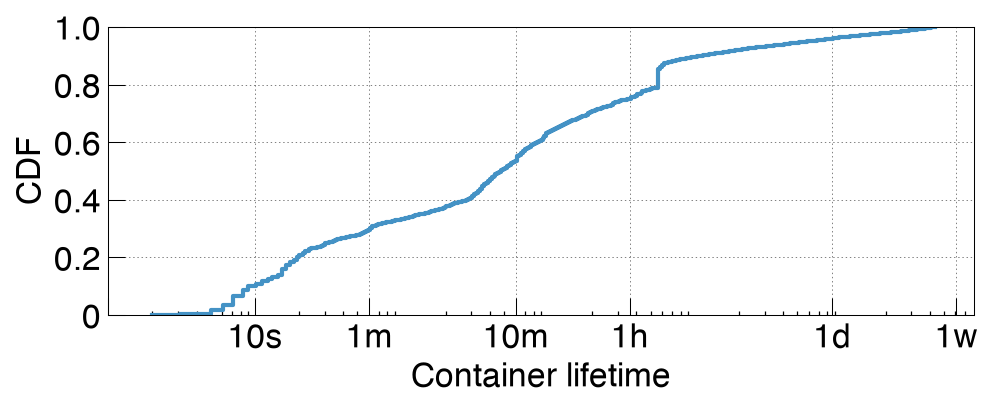

Container lifetime < 10 min: 53.6% of pods; < 1 hour: 75.3%


In [8]:
lifetimes = aggregates["lifetimes"]
n = selected["pods"]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
plot_time_cdf(ax, [(lifetimes["lifetime_ms"] / 1000, lifetimes["pods"], "CaaS")],
              "Container lifetime", "CDF")
ax.get_legend().remove()
hide_first_x_label(ax)
plt.show()
print(f"Container lifetime < 10 min: {selected['lifetime_below_10min'] / n:.1%} of pods; "
      f"< 1 hour: {selected['lifetime_below_1hour'] / n:.1%}")

## Request volume

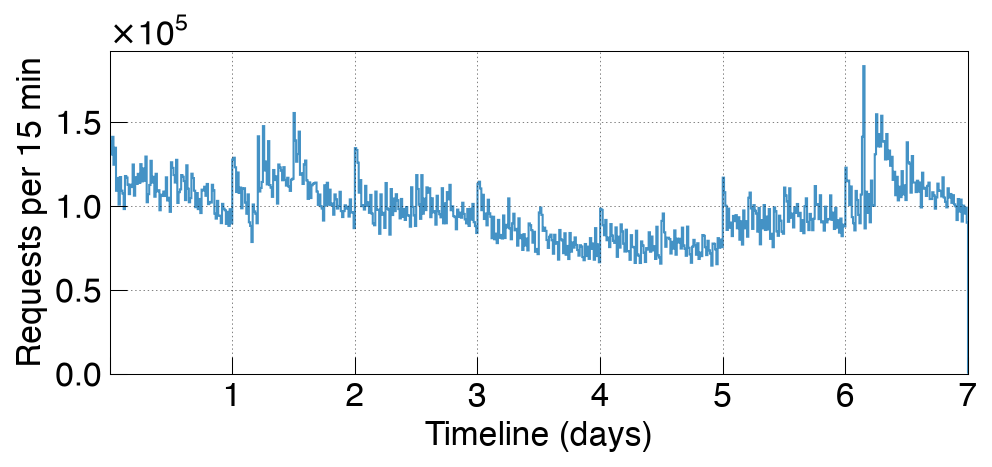

In [9]:
windows = aggregates["windows"]
edges = [i / SHARDS_PER_DAY for i in range(len(windows) + 1)]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.stairs(windows["pods"], edges, label="CaaS")
ax.set_xticks(range(8))
ax.set(xlim=(0, 7), ylim=(0, None), xlabel="Timeline (days)", ylabel="Requests per 15 min")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
hide_first_x_label(ax)
plt.show()

## Request arrivals

Pods with the same `container_group_id` form a pool, regardless of namespace. For pools with at least
two pods, we plot the minimum, mean, and maximum inter-arrival time (IAT) between consecutive pod creations.

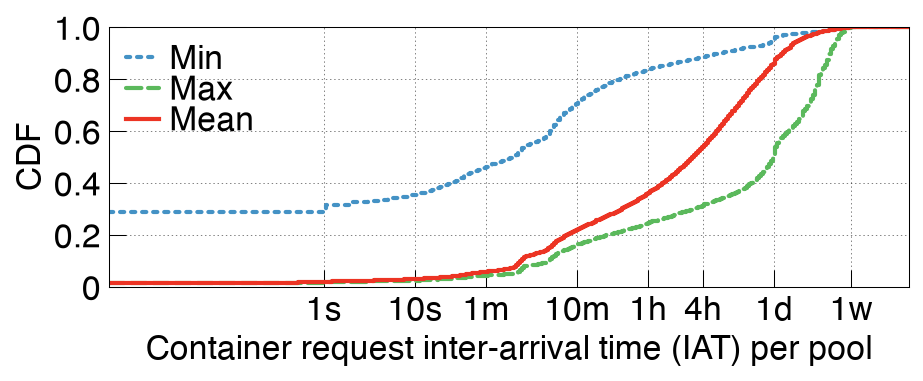

Mean IAT > 1 min: 94.3% of pools; > 1 hour: 63.9%


In [10]:
iats = aggregates["pools"]
k = selected["valid_bundles"]
curves = []
for column, name in [("min_iat_s", "Min"), ("max_iat_s", "Max"), ("mean_iat_s", "Mean")]:
    counts = iats[column].value_counts()
    curves.append((counts.index, counts.to_numpy(), name))
with plt.rc_context({"figure.constrained_layout.use": False}):
    fig, ax = plt.subplots(figsize=(6.5, 2.6))
    fig.subplots_adjust(left=0.132, right=0.952, bottom=0.26, top=0.925)
    plot_time_cdf(ax, curves, "Container request inter-arrival time (IAT) per pool", "CDF",
                  domain=(1 / 224, 30 * 86400))
    for line, color, style in zip(ax.lines, ("#4492c5", "#5bb95c", "#ec3424"), (":", "--", "-")):
        line.set(color=color, linestyle=style, linewidth=2, dash_capstyle="round")
    ax.set_xticks([1, 10, 60, 600, 3600, 14400, 86400, 604800],
                  ["1s", "10s", "1m", "10m", "1h", "4h", "1d", "1w"])
    ax.minorticks_off()
    ax.tick_params(direction="in", length=8, width=0.5, pad=4)
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)
    ax.grid(True, color="black", alpha=0.6, linewidth=0.4, linestyle=(0, (1, 4)))
    ax.legend(loc="upper left", frameon=False, handlelength=1, handletextpad=0.3,
              borderpad=0, labelspacing=0)
    plt.show()
print(f"Mean IAT > 1 min: {selected['mean_iat_above_1min'] / k:.1%} of pools; "
      f"> 1 hour: {selected['mean_iat_above_1hour'] / k:.1%}")

## CPU and memory

We plot CPU and memory requests and limits, omitting missing limits. In the released trace,
positive values are rounded down to powers of two.

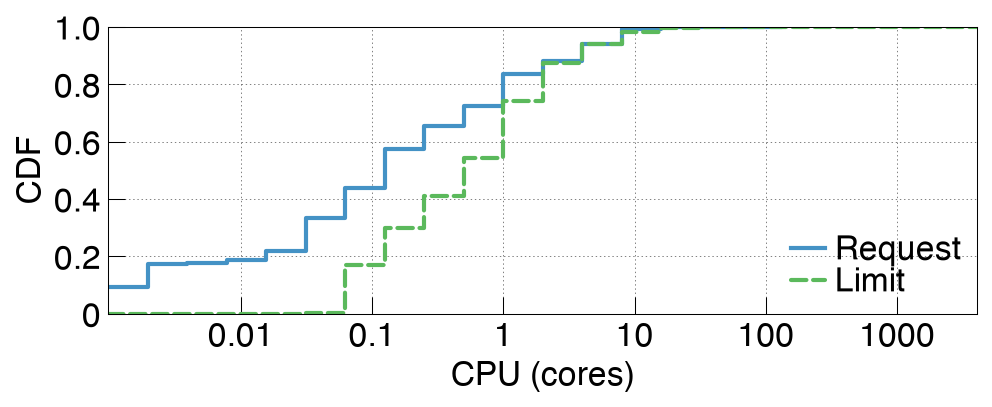

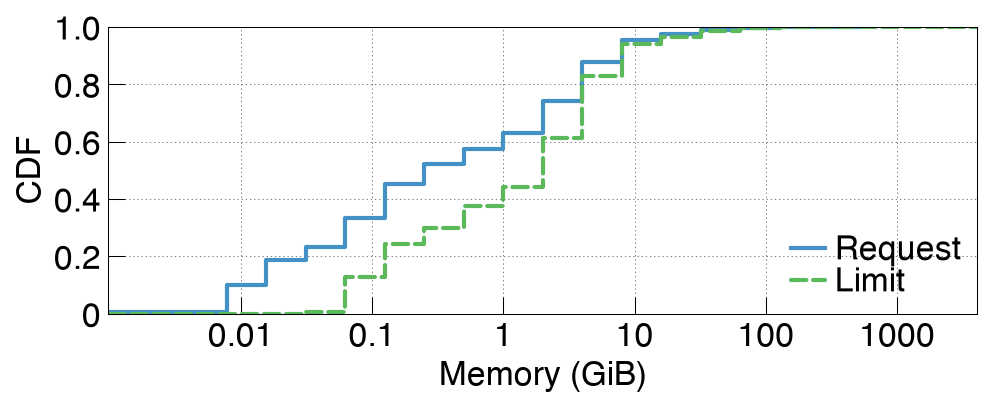

In [11]:
resources = aggregates["resources"]
for xlabel, columns in [("CPU (cores)", ("requested_cpu", "limit_cpu")),
                        ("Memory (GiB)", ("requested_memory_mib", "limit_memory_mib"))]:
    fig, ax = plt.subplots(figsize=(6.5, 2.6))
    for column, label, style in zip(columns, ("Request", "Limit"), ("-", "--")):
        x, y = cdf_curve(resources[column]["amount"], resources[column]["pods"])
        ax.step(x, y, where="post", linestyle=style, label=label)
    ax.set_xscale("log", base=2)
    ax.set_xticks([0.01, 0.1, 1, 10, 100, 1000], ["0.01", "0.1", "1", "10", "100", "1000"])
    ax.set(xlim=(1 / 1024, max(resources[c]["amount"].max() for c in columns)),
           ylim=(0, 1), xlabel=xlabel, ylabel="CDF")
    ax.minorticks_off()
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1], ["0", "0.2", "0.4", "0.6", "0.8", "1.0"])
    ax.legend(loc="lower right")
    plt.show()

If you find this trace useful, please cite the dataset and our paper ([BibTeX](citation.bib)). Data: [CC-BY 4.0](../../LICENSE);
code: [MIT](../../LICENSE-CODE).